In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.dates as mdates


In [ ]:
# @title
import numpy as np

class PumaState:
    """
    Manages the historical performance memory and phase-switching logic
    for the Puma Optimizer.
    """
    def __init__(self):
        # Weights for the scoring functions (PF_1, PF_2, PF_3)
        self.PF = np.array([0.67, 0.67, 0.42])

        # Historical arrays for the last 3 steps [t, t-1, t-2]
        self.time_explore = np.ones(3)
        self.time_exploit = np.ones(3)
        self.cost_explore = np.ones(3)
        self.cost_exploit = np.ones(3)

        # Unselected counters [explore, exploit]
        self.unselected = np.ones(2)

        # F3 Accumulators (Diversification components)
        self.F3_explore = 0.0
        self.F3_exploit = 0.0

        # Adaptive Weights
        self.mega_explore = 0.99
        self.mega_exploit = 0.99

        self.pf_f3_history = []
        self.current_phase = 1 # 1 = Explore, 2 = Exploit

    def shift_history(self, cost_history, time_history, new_cost, unselected_count):
        """Helper to shift the [t-2, t-1, t] arrays back in time."""
        cost_history[2] = cost_history[1]
        cost_history[1] = cost_history[0]
        cost_history[0] = new_cost

        time_history[2] = time_history[1]
        time_history[1] = time_history[0]
        time_history[0] = unselected_count

    def calculate_scores(self):
        """Calculates F1, F2, and the final Score for both phases."""
        # F1: Immediate return on investment
        f1_explore = self.PF[0] * (self.cost_explore[0] / self.time_explore[0])
        f1_exploit = self.PF[0] * (self.cost_exploit[0] / self.time_exploit[0])

        # F2: Historical return on investment
        f2_explore = self.PF[1] * (np.sum(self.cost_explore) / np.sum(self.time_explore))
        f2_exploit = self.PF[1] * (np.sum(self.cost_exploit) / np.sum(self.time_exploit))

        # F3: Minimum observed nonzero cost change
        min_pf_f3 = min(self.pf_f3_history) if self.pf_f3_history else 0.0

        lmn_explore = 1 - self.mega_explore
        lmn_exploit = 1 - self.mega_exploit

        score_explore = (self.mega_explore * f1_explore) + (self.mega_explore * f2_explore) + (lmn_explore * min_pf_f3 * self.F3_explore)
        score_exploit = (self.mega_exploit * f1_exploit) + (self.mega_exploit * f2_exploit) + (lmn_exploit * min_pf_f3 * self.F3_exploit)

        return score_explore, score_exploit

    def adapt_weights(self, score_explore, score_exploit):
        """Adjusts the 'Mega' weights based on which score is winning."""
        if score_explore < score_exploit:
            # Explore is losing: penalize explore, reset exploit
            self.mega_explore = max(self.mega_explore - 0.01, 0.01)
            self.mega_exploit = 0.99

        elif score_explore > score_exploit:
            # Exploit is losing: penalize exploit, reset explore
            self.mega_explore = 0.99
            self.mega_exploit = max(self.mega_exploit - 0.01, 0.01)

def run_puma_optimizer(n_agents, max_iter, dim, lower_bound, upper_bound, cost_function, seed=42):
    rng = np.random.default_rng(seed)

    # Initialization
    population = rng.uniform(lower_bound, upper_bound, size=(n_agents, dim))
    fitness = np.zeros(n_agents)
    for i in range(n_agents):
        fitness[i] = cost_function(population[i])

    best_idx = np.argmin(fitness)
    global_best_pos = population[best_idx].copy()
    global_best_cost = fitness[best_idx]

    convergence_curve = np.zeros(max_iter)

    population_history = []

    state = PumaState()
    pCR = 0.20

    print("\n--- Starting Puma Optimization ---")

    for iteration in range(max_iter):

        if iteration < 3:
            # ---------------------------------------------------------
            # UNEXPERIENCED PHASE: Strict fidelity to MATLAB/PO Paper
            # ---------------------------------------------------------
            # 1. Run Exploration Branch
            pop_explor, fit_explor, pCR = exploration_phase(
                population, fitness, lower_bound, upper_bound, cost_function, pCR, rng
            )
            best_explor_cost = np.min(fit_explor)

            # 2. Run Exploitation Branch
            pop_exploit, fit_exploit = exploitation_phase(
                population, fitness, lower_bound, upper_bound, global_best_pos,
                iteration, max_iter, cost_function, rng
            )
            best_exploit_cost = np.min(fit_exploit)

            # 3. Pool and Sort (Sol + Sol_Explor + Sol_Exploit)
            all_pops = np.vstack((population, pop_explor, pop_exploit))
            all_fits = np.concatenate((fitness, fit_explor, fit_exploit))

            # Sort all 3N agents by fitness and keep only the top N
            sorted_indices = np.argsort(all_fits)[:n_agents]
            population = all_pops[sorted_indices]
            fitness = all_fits[sorted_indices]

            # 4. Update history arrays for BOTH phases
            cost_diff_explor = abs(global_best_cost - best_explor_cost)
            cost_diff_exploit = abs(global_best_cost - best_exploit_cost)

            state.shift_history(state.cost_explore, state.time_explore, cost_diff_explor, 1)
            state.shift_history(state.cost_exploit, state.time_exploit, cost_diff_exploit, 1)

            if cost_diff_explor > 0: state.pf_f3_history.append(cost_diff_explor)
            if cost_diff_exploit > 0: state.pf_f3_history.append(cost_diff_exploit)

            phase_str = "Unexperienced (Both)"

        else:
            # ---------------------------------------------------------
            # EXPERIENCED PHASE: Adaptive Phase Switching
            # ---------------------------------------------------------
            score_explore, score_exploit = state.calculate_scores()

            if score_explore > score_exploit:
                population, fitness, pCR = exploration_phase(
                    population, fitness, lower_bound, upper_bound, cost_function, pCR, rng
                )

                # Update State Trackers
                state.unselected[1] += 1
                state.F3_explore = state.PF[2]
                state.F3_exploit += state.PF[2]

                iter_best_idx = np.argmin(fitness)
                cost_diff = abs(global_best_cost - fitness[iter_best_idx])

                state.shift_history(state.cost_explore, state.time_explore, cost_diff, state.unselected[0])
                state.unselected[0] = 1
                if cost_diff > 0: state.pf_f3_history.append(cost_diff)
                phase_str = "Experienced (Explore)"

            else:
                population, fitness = exploitation_phase(
                    population, fitness, lower_bound, upper_bound, global_best_pos,
                    iteration, max_iter, cost_function, rng
                )

                # Update State Trackers
                state.unselected[0] += 1
                state.F3_exploit = state.PF[2]
                state.F3_explore += state.PF[2]

                iter_best_idx = np.argmin(fitness)
                cost_diff = abs(global_best_cost - fitness[iter_best_idx])

                state.shift_history(state.cost_exploit, state.time_exploit, cost_diff, state.unselected[1])
                state.unselected[1] = 1
                if cost_diff > 0: state.pf_f3_history.append(cost_diff)
                phase_str = "Experienced (Exploit)"

            # Adapt weights for the next round
            state.adapt_weights(score_explore, score_exploit)

        # Update Global Best
        current_best_idx = np.argmin(fitness)
        if fitness[current_best_idx] < global_best_cost:
            global_best_cost = fitness[current_best_idx]
            global_best_pos = population[current_best_idx].copy()

        convergence_curve[iteration] = global_best_cost
        print(f"Iteration {iteration + 1}/{max_iter} - Phase: {phase_str} - Best Loss: {global_best_cost:.6f}")
        population_history.append(population.copy())

    return global_best_pos, global_best_cost, convergence_curve, population_history

def exploration_phase(population, fitness, lower_bound, upper_bound, cost_function, pCR, rng):
    """
    Executes the Global Search (Exploration) phase using Differential Evolution logic.
    """
    n_agents, dim = population.shape
    new_population = population.copy()

    # Base crossover increment factor from the PO paper
    p = (1 - pCR) / n_agents

    for i in range(n_agents):
        # 1. Pick 6 random distinct agents (excluding current agent 'i')
        indices = np.delete(np.arange(n_agents), i)
        a, b, c, d, e, f = rng.choice(indices, size=6, replace=False)

        # 2. Extract their positions
        xa, xb, xc = population[a], population[b], population[c]
        xd, xe, xf = population[d], population[e], population[f]

        # 3. Calculate the Differential Mutation
        G = 2 * rng.random() - 1
        if rng.random() < 0.5:
            # Pure random search jump
            y = rng.uniform(lower_bound, upper_bound, size=dim)
        else:
            # Puma differential search jump
            term1 = xa - xb
            term2 = (xa - xb) - (xc - xd)
            term3 = (xc - xd) - (xe - xf)
            y = xa + G * term1 + G * (term2 + term3)

        # Enforce boundaries
        y = np.clip(y, lower_bound, upper_bound)

        # 4. Crossover: Mix the mutated vector 'y' with the original vector 'x'
        z = population[i].copy()
        j_rand = rng.integers(0, dim) # Guarantee at least one mutated feature

        for j in range(dim):
            if j == j_rand or rng.random() <= pCR:
                z[j] = y[j]

        # 5. Greedy Selection: Keep the new position only if it improves the loss
        new_cost = cost_function(z)
        if new_cost < fitness[i]:
            new_population[i] = z
            fitness[i] = new_cost
        else:
            # PO adaptively increases crossover probability if the search fails
            pCR += p

    return new_population, fitness, pCR

def exploitation_phase(population, fitness, lower_bound, upper_bound, global_best_pos, current_iter, max_iter, cost_function, rng):
    """
    Executes the Local Search (Exploitation) phase using Puma attack mechanics.
    """
    n_agents, dim = population.shape
    new_population = population.copy()

    Q = 0.67  # 'L' from the PO paper: branch threshold
    beta = 2  # 'a' from the PO paper: denominator scaling factor

    # Calculate the mean position across all coordinates of all agents
    # (Preserving the specific MATLAB behavior where mean is a single scalar)
    mbest = np.mean(population) / n_agents

    for i in range(n_agents):
        current_pos = population[i]

        # 1. Generate random PO scaling vectors
        beta1 = 2 * rng.random()
        beta2 = rng.standard_normal(dim)
        w = rng.standard_normal(dim)
        v = rng.standard_normal(dim)

        F1_vec = rng.standard_normal(dim) * np.exp(2 - current_iter * (2 / max_iter))
        F2_vec = w * (v**2) * np.cos((2 * rng.random()) * w)
        R_1 = 2 * rng.random() - 1

        # 2. Calculate the "Attack Vector" (VEC)
        # This translates MATLAB's matrix right-division (S2 / S1) to Python dot products
        S1 = (2 * rng.random() - 1) + rng.standard_normal(dim)
        S2 = (F1_vec * R_1 * current_pos) + (F2_vec * (1 - R_1) * global_best_pos)

        denominator = np.dot(S1, S1)
        # Prevent division by zero
        vec_attack = np.dot(S2, S1) / denominator if denominator != 0 else 0.0

        # 3. Apply the Puma Movement Logic
        if rng.random() <= 0.5:
            if rng.random() > Q:
                r2 = rng.integers(0, n_agents)
                new_x = global_best_pos + beta1 * np.exp(beta2) * (population[r2] - current_pos)
            else:
                new_x = beta1 * vec_attack - global_best_pos
        else:
            r1 = rng.integers(0, n_agents)
            sign_flip = rng.choice([-1, 1])
            new_x = (mbest * population[r1] - sign_flip * current_pos) / (1 + beta * rng.random())

        # 4. Enforce boundaries
        new_x = np.clip(new_x, lower_bound, upper_bound)

        # 5. Greedy Selection
        new_cost = cost_function(new_x)
        if new_cost < fitness[i]:
            new_population[i] = new_x
            fitness[i] = new_cost

    # ADD THIS RETURN STATEMENT AT THE END (aligned with the outer for-loop)
    return new_population, fitness




# 1. DATA ACQUISITION & SLIDING WINDOW

In [ ]:
def fetch_data(ticker, period="5y", interval="1d"):
    df = yf.download(ticker, period=period, interval=interval, auto_adjust=False)
    return df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].dropna()

def create_sliding_window(df, window_size=30):
    """
    Mengubah data tabular menjadi format 3D sliding window.
    Input: df (DataFrame harga)
    Output: X (samples, window_size, features), y (target log return)
    """
    data = df.values
    target = np.log(df["Close"] / df["Close"].shift(1)).values # Log Return sebagai target

    X, y = [], []
    # Mulai dari window_size karena kita butuh data masa lalu
    for i in range(window_size, len(data) - 1):
        X.append(data[i-window_size:i, :]) # Ambil 30 hari ke belakang
        y.append(target[i+1])              # Prediksi return besok

    return np.array(X), np.array(y).reshape(-1, 1)

def split_and_scale(X, y):
    n = len(X)
    tr_end, val_end = int(0.70 * n), int(0.85 * n)

    X_tr, y_tr = X[:tr_end], y[:tr_end]
    X_val, y_val = X[tr_end:val_end], y[tr_end:val_end]
    X_te, y_te = X[val_end:], y[val_end:]

    # Scaling (Fit hanya di Train)
    # Karena X berbentuk 3D (samples, window, features), kita perlu reshape sementara ke 2D
    n_samples, window, n_feats = X.shape
    X_tr_2d = X_tr.reshape(-1, n_feats)
    sx = MinMaxScaler().fit(X_tr_2d)

    sy = MinMaxScaler().fit(y_tr)

    # Transform dan kembalikan ke bentuk 3D
    X_tr_scaled = sx.transform(X_tr.reshape(-1, n_feats)).reshape(X_tr.shape)
    X_val_scaled = sx.transform(X_val.reshape(-1, n_feats)).reshape(X_val.shape)
    X_te_scaled = sx.transform(X_te.reshape(-1, n_feats)).reshape(X_te.shape)

    return (X_tr_scaled, sy.transform(y_tr),
            X_val_scaled, sy.transform(y_val),
            X_te_scaled, sy.transform(y_te), sx, sy)

# 2. ARSITEKTUR MLP (DENGAN FLATTEN)

In [ ]:
"""# 2. ARSITEKTUR MLP (3 HIDDEN LAYERS: 128, 64, 32)"""

WINDOW_SIZE = 10
N_FEATURES = 6  # Explicitly updated to 6 to include all your downloaded columns
FLATTEN_SIZE = WINDOW_SIZE * N_FEATURES

# Calculate Total Parameters (D) dynamically
w1_params = (FLATTEN_SIZE * 128) + 128
w2_params = (128 * 64) + 64
w3_params = (64 * 32) + 32
w4_params = (32 * 1) + 1

D = w1_params + w2_params + w3_params + w4_params
print(f"[*] Dynamic Total Parameters (D): {D}")

def unpack(theta):
    i = 0
    # Layer 1
    W1 = theta[i:i + (FLATTEN_SIZE * 128)].reshape(FLATTEN_SIZE, 128); i += (FLATTEN_SIZE * 128)
    b1 = theta[i:i + 128]; i += 128
    # Layer 2
    W2 = theta[i:i + (128 * 64)].reshape(128, 64); i += (128 * 64)
    b2 = theta[i:i + 64]; i += 64
    # Layer 3
    W3 = theta[i:i + (64 * 32)].reshape(64, 32); i += (64 * 32)
    b3 = theta[i:i + 32]; i += 32
    # Output Layer
    W4 = theta[i:i + 32].reshape(32, 1); i += 32
    b4 = theta[i:i + 1]
    return W1, b1, W2, b2, W3, b3, W4, b4

def mlp_forward(theta, X):
    # X berbentuk (samples, 30, 4) -> kita ratakan (flatten) menjadi (samples, 120)
    X_flat = X.reshape(X.shape[0], -1)
    W1, b1, W2, b2, W3, b3, W4, b4 = unpack(theta)

    # Forward pass melalui 3 hidden layer
    h1 = np.tanh(X_flat @ W1 + b1)
    h2 = np.tanh(h1 @ W2 + b2)
    h3 = np.tanh(h2 @ W3 + b3)
    out = h3 @ W4 + b4
    return out

def fitness(theta, X, y):
    mse = np.mean((y - mlp_forward(theta, X)) ** 2)
    return np.sqrt(mse)

[*] Dynamic Total Parameters (D): 18177


# 3. PO OPTIMIZER

In [ ]:
def create_po_cost(X, y):
    """Wraps the existing fitness function so PO only passes 'theta'."""
    def cost_function(theta):
        return fitness(theta, X, y)
    return cost_function

In [ ]:
def po_optimize(X_train, y_train, X_val, y_val, N=150, T=200, bounds=(-1.0, 1.0), seed=67, patience=40):
    # Note: We keep the function name '' to avoid breaking the pipeline,
    # but we execute the Puma Optimizer inside.

    # 1. Lock in the training data for the cost function
    train_cost = create_po_cost(X_train, y_train)

    # 2. Execute Puma Optimizer
    best_theta, best_cost, convergence_curve, _ = run_puma_optimizer(
        n_agents=N,
        max_iter=T,
        dim=D,  # Uses the global D (25857) defined in your script
        lower_bound=bounds[0],
        upper_bound=bounds[1],
        cost_function=train_cost,
        seed=seed
    )

    # 3. Calculate final validation fitness for the return signature
    best_val_cost = fitness(best_theta, X_val, y_val)

    # Return best weights, validation score, and convergence history
    return best_theta, best_val_cost, convergence_curve

# 4. BACKPROPAGATION (Adam) DENGAN FLATTEN

In [ ]:
"""# 4. BACKPROPAGATION (Adam) DENGAN 3 HIDDEN LAYERS"""

def train_mlp_backprop(X_train, y_train, X_val, y_val, epochs=100, lr=0.01):
    X_tr_t = torch.FloatTensor(X_train.reshape(X_train.shape[0], -1))
    y_tr_t = torch.FloatTensor(y_train)
    X_val_t = torch.FloatTensor(X_val.reshape(X_val.shape[0], -1))
    y_val_t = torch.FloatTensor(y_val)

    class MLP(nn.Module):
        def __init__(self):
            super(MLP, self).__init__()
            self.net = nn.Sequential(
                nn.Linear(FLATTEN_SIZE, 128),
                nn.Tanh(),
                nn.Linear(128, 64),
                nn.Tanh(),
                nn.Linear(64, 32),
                nn.Tanh(),
                nn.Linear(32, 1)
            )
        def forward(self, x):
            return self.net(x)

    model = MLP()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history_mse = []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_tr_t)
        loss = criterion(y_pred, y_tr_t)
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0 or epoch == epochs - 1:
            model.eval()
            with torch.no_grad():
                val_pred = model(X_val_t)
                val_loss = criterion(val_pred, y_val_t).item()
                history_mse.append(val_loss)

    train_time = time.time() - start_time
    return model, history_mse, train_time

# 5. PIPELINE UTAMA

In [ ]:
def run_comparative_pipeline(ticker):
    print(f"\n--- Memproses {ticker} ---")
    df = fetch_data(ticker)

    # Buat Sliding Window
    X, y = create_sliding_window(df, window_size=WINDOW_SIZE)
    print(f"Bentuk X setelah sliding window: {X.shape}") # (samples, 30, 4)

    # Simpan harga Close asli untuk rekonstruksi
    close_prices = df["Close"].values[WINDOW_SIZE:].ravel() # Pastikan 1D

    X_tr, y_tr, X_val, y_val, X_te, y_te, sx, sy = split_and_scale(X, y)

    # 1. Latih Puma Optimizer (Menggunakan fungsi wrapper)
    print("Melatih dengan Puma Optimizer...")
    start_po = time.time()
    theta, f_best, eefo_log = po_optimize(X_tr, y_tr, X_val, y_val)
    time_eefo = time.time() - start_po

    # 2. Latih Backprop
    print("Melatih dengan Backpropagation (Adam)...")
    model_bp, bp_log, time_bp = train_mlp_backprop(X_tr, y_tr, X_val, y_val, epochs=200, lr=0.01)

    # 3. Rekonstruksi Harga
    n = len(X)
    tr_end, val_end = int(0.70 * n), int(0.85 * n)

    # Index untuk test set
    close_yesterday_test = close_prices[val_end : -1].ravel()
    close_actual_test = close_prices[val_end + 1 :].ravel()

    y_pred_eefo_log_ret = sy.inverse_transform(mlp_forward(theta, X_te)).ravel()

    model_bp.eval()
    with torch.no_grad():
        y_pred_bp_log_ret = sy.inverse_transform(model_bp(torch.FloatTensor(X_te.reshape(X_te.shape[0], -1))).numpy()).ravel()

    y_pred_eefo_price = (close_yesterday_test * np.exp(y_pred_eefo_log_ret)).ravel()
    y_pred_bp_price = (close_yesterday_test * np.exp(y_pred_bp_log_ret)).ravel()
    y_true_price = close_actual_test.ravel()

    # 4. Metrik
    def calc_metrics(y_true, y_pred):
        return {
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
            "R2": r2_score(y_true, y_pred)
        }

    metrics_eefo = calc_metrics(y_true_price, y_pred_eefo_price)
    metrics_bp = calc_metrics(y_true_price, y_pred_bp_price)

    print(f"Waktu EEFO: {time_eefo:.2f} detik | Waktu BP: {time_bp:.2f} detik")
    print(f"Metrik EEFO: {metrics_eefo}")
    print(f"Metrik BP  : {metrics_bp}")

    return {
        "eefo": {"metrics": metrics_eefo, "time": time_eefo, "log": eefo_log, "pred": y_pred_eefo_price},
        "bp": {"metrics": metrics_bp, "time": time_bp, "log": bp_log, "pred": y_pred_bp_price},
        "y_true": y_true_price
    }

In [ ]:
# --- 6. VISUALIZATION & EXPORT FUNCTIONS ---
def generate_comparative_plots(results_compare, tickers):
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates

    # Redesigned Matplotlib Aesthetic
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'axes.facecolor': '#FAFAFA',
        'figure.facecolor': '#FFFFFF',
        'axes.grid': True,
        'grid.color': '#E0E0E0',
        'grid.linestyle': '-.',
        'grid.alpha': 0.7,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.spines.left': True,
        'axes.spines.bottom': True,
        'axes.edgecolor': '#BDBDBD',
        'axes.linewidth': 1.2
    })

    # --- Plot Konvergensi ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors_po = ['#007AFF', '#FF9500', '#34C759']
    colors_bp = ['#FF3B30', '#AF52DE', '#8E8E93']

    for i, ticker in enumerate(tickers):
        axes[i].plot(results_compare[ticker]["eefo"]["log"], label="Puma Optimizer", color=colors_po[i], linewidth=2.5)

        bp_iters = np.linspace(0, len(results_compare[ticker]["eefo"]["log"]), len(results_compare[ticker]["bp"]["log"]))
        axes[i].plot(bp_iters, results_compare[ticker]["bp"]["log"], label="Backprop (Adam)", color=colors_bp[i], linestyle='--', linewidth=2, alpha=0.8)

        axes[i].set_title(f"{ticker}: Convergence MSE", fontsize=13, fontweight='600', pad=10)
        axes[i].set_xlabel("Iteration / Epoch (Scaled)", fontsize=11, color='#424242')
        axes[i].set_ylabel("MSE (Log Scale)", fontsize=11, color='#424242')
        axes[i].set_yscale("log")

        legend = axes[i].legend(frameon=True, facecolor='#FFFFFF', edgecolor='#E0E0E0', framealpha=0.9)
        legend.get_frame().set_linewidth(1.0)

    plt.tight_layout()
    plt.savefig("po_vs_backprop_convergence_3assets.png", dpi=150, bbox_inches='tight')
    plt.show()

    # --- Plot Harga Aktual vs Prediksi ---
    fig, axes = plt.subplots(3, 2, figsize=(16, 15))
    for i, ticker in enumerate(tickers):
        y_true = results_compare[ticker]["y_true"]
        y_po = results_compare[ticker]["eefo"]["pred"]
        y_bp = results_compare[ticker]["bp"]["pred"]

        axes[i, 0].plot(y_true, label="Actual", color='#1C1C1E', linewidth=2, zorder=3)
        axes[i, 0].plot(y_po, label=f"Puma Optimizer (R²={results_compare[ticker]['eefo']['metrics']['R2']:.3f})", color='#007AFF', linestyle='-.', linewidth=2, zorder=2)
        axes[i, 0].fill_between(range(len(y_true)), y_true, alpha=0.05, color='#1C1C1E', zorder=1)
        axes[i, 0].set_title(f"{ticker}: Actual vs Puma Optimizer", fontsize=12, fontweight='600')
        axes[i, 0].legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#E0E0E0', framealpha=0.9)

        axes[i, 1].plot(y_true, label="Actual", color='#1C1C1E', linewidth=2, zorder=3)
        axes[i, 1].plot(y_bp, label=f"Backprop (R²={results_compare[ticker]['bp']['metrics']['R2']:.3f})", color='#FF9500', linestyle='--', linewidth=2, zorder=2)
        axes[i, 1].fill_between(range(len(y_true)), y_true, alpha=0.05, color='#1C1C1E', zorder=1)
        axes[i, 1].set_title(f"{ticker}: Actual vs Backprop", fontsize=12, fontweight='600')
        axes[i, 1].legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#E0E0E0', framealpha=0.9)

    plt.suptitle("Price Prediction Comparison on Test Set", fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig("actual_vs_predicted_3assets.png", dpi=200, bbox_inches='tight')
    plt.show()

def export_research_data_to_csv(results_compare, tickers):
    import pandas as pd
    print("\n[*] Exporting all evaluation metrics and predictions to CSV...")

    # 1. Export Metrics
    metrics_data = []
    for ticker in tickers:
        for method in ["eefo", "bp"]:
            metrics = results_compare[ticker][method]["metrics"]
            metrics_data.append({
                "Ticker": ticker,
                "Method": "Puma Optimizer (PO)" if method == "eefo" else "Backprop (Adam)",
                "RMSE": metrics["RMSE"],
                "MAE": metrics["MAE"],
                "MAPE": metrics["MAPE"],
                "R2": metrics["R2"],
                "Training_Time_Sec": results_compare[ticker][method]["time"]
            })
    pd.DataFrame(metrics_data).to_csv("evaluation_metrics_summary.csv", index=False)

    # 2. Export Forecasts
    forecast_data = []
    for ticker in tickers:
        y_true = results_compare[ticker]["y_true"].ravel()
        y_po = results_compare[ticker]["eefo"]["pred"].ravel()
        y_bp = results_compare[ticker]["bp"]["pred"].ravel()

        df_ticker = pd.DataFrame({
            "Ticker": ticker,
            "Test_Day": range(1, len(y_true) + 1),
            "Actual_Price": y_true,
            "PO_Predicted_Price": y_po,
            "Backprop_Predicted_Price": y_bp
        })
        forecast_data.append(df_ticker)
    pd.concat(forecast_data, ignore_index=True).to_csv("actual_vs_predicted_forecasts.csv", index=False)

    # 3. Export Convergence
    convergence_data = []
    for ticker in tickers:
        po_log = results_compare[ticker]["eefo"]["log"]
        convergence_data.append(pd.DataFrame({
            "Ticker": ticker, "Method": "Puma Optimizer (PO)",
            "Iteration": range(1, len(po_log) + 1), "MSE_Loss": po_log
        }))

        bp_log = results_compare[ticker]["bp"]["log"]
        convergence_data.append(pd.DataFrame({
            "Ticker": ticker, "Method": "Backprop (Adam)",
            "Logged_Step": range(1, len(bp_log) + 1), "MSE_Loss": bp_log
        }))
    pd.concat(convergence_data, ignore_index=True).to_csv("training_convergence_history.csv", index=False)
    print("[+] CSV exports complete.")


--- Memproses NVDA ---


[*********************100%***********************]  1 of 1 completed


Bentuk X setelah sliding window: (1244, 10, 6)
Melatih dengan Puma Optimizer...

--- Starting Puma Optimization ---
Iteration 1/200 - Phase: Unexperienced (Both) - Best Loss: 0.237407
Iteration 2/200 - Phase: Unexperienced (Both) - Best Loss: 0.111796
Iteration 3/200 - Phase: Unexperienced (Both) - Best Loss: 0.106365
Iteration 4/200 - Phase: Experienced (Exploit) - Best Loss: 0.106365
Iteration 5/200 - Phase: Experienced (Exploit) - Best Loss: 0.106365
Iteration 6/200 - Phase: Experienced (Exploit) - Best Loss: 0.106365
Iteration 7/200 - Phase: Experienced (Explore) - Best Loss: 0.106365
Iteration 8/200 - Phase: Experienced (Exploit) - Best Loss: 0.106365
Iteration 9/200 - Phase: Experienced (Explore) - Best Loss: 0.106365
Iteration 10/200 - Phase: Experienced (Exploit) - Best Loss: 0.106365
Iteration 11/200 - Phase: Experienced (Explore) - Best Loss: 0.090869
Iteration 12/200 - Phase: Experienced (Explore) - Best Loss: 0.090869
Iteration 13/200 - Phase: Experienced (Explore) - Best L

[*********************100%***********************]  1 of 1 completed

Waktu EEFO: 495.01 detik | Waktu BP: 0.86 detik
Metrik EEFO: {'RMSE': np.float64(4.9622906259955695), 'MAE': 3.8804601084663974, 'MAPE': np.float64(1.8919164641623416), 'R2': 0.9161928286651676}
Metrik BP  : {'RMSE': np.float64(5.2430691611004585), 'MAE': 4.091424475363095, 'MAPE': np.float64(1.986286654709494), 'R2': 0.9064404846029248}

--- Memproses BBCA.JK ---
Bentuk X setelah sliding window: (1189, 10, 6)
Melatih dengan Puma Optimizer...



--- Starting Puma Optimization ---
Iteration 1/200 - Phase: Unexperienced (Both) - Best Loss: 0.196885
Iteration 2/200 - Phase: Unexperienced (Both) - Best Loss: 0.174586
Iteration 3/200 - Phase: Unexperienced (Both) - Best Loss: 0.100430
Iteration 4/200 - Phase: Experienced (Exploit) - Best Loss: 0.100430
Iteration 5/200 - Phase: Experienced (Exploit) - Best Loss: 0.100430
Iteration 6/200 - Phase: Experienced (Exploit) - Best Loss: 0.100430
Iteration 7/200 - Phase: Experienced (Explore) - Best Loss: 0.100430
Iteration 8/200 - Phase: Experienced (Exploit) - Best Loss: 0.098959
Iteration 9/200 - Phase: Experienced (Exploit) - Best Loss: 0.098959
Iteration 10/200 - Phase: Experienced (Exploit) - Best Loss: 0.098959
Iteration 11/200 - Phase: Experienced (Exploit) - Best Loss: 0.098959
Iteration 12/200 - Phase: Experienced (Explore) - Best Loss: 0.098959
Iteration 13/200 - Phase: Experienced (Exploit) - Best Loss: 0.098959
Iteration 14/200 - Phase: Experienced (Explore) - Best Loss: 0.098

[*********************100%***********************]  1 of 1 completed

Waktu EEFO: 495.17 detik | Waktu BP: 0.57 detik
Metrik EEFO: {'RMSE': np.float64(669.7001803742878), 'MAE': 590.5140465701451, 'MAPE': np.float64(9.636289231297875), 'R2': -0.30117065165857393}
Metrik BP  : {'RMSE': np.float64(243.79535012267993), 'MAE': 197.05304334283542, 'MAPE': np.float64(3.2017143228785017), 'R2': 0.8275654597346618}

--- Memproses TSLA ---
Bentuk X setelah sliding window: (1244, 10, 6)
Melatih dengan Puma Optimizer...



--- Starting Puma Optimization ---
Iteration 1/200 - Phase: Unexperienced (Both) - Best Loss: 0.191914
Iteration 2/200 - Phase: Unexperienced (Both) - Best Loss: 0.184731
Iteration 3/200 - Phase: Unexperienced (Both) - Best Loss: 0.151108
Iteration 4/200 - Phase: Experienced (Exploit) - Best Loss: 0.130639
Iteration 5/200 - Phase: Experienced (Exploit) - Best Loss: 0.130639
Iteration 6/200 - Phase: Experienced (Exploit) - Best Loss: 0.130122
Iteration 7/200 - Phase: Experienced (Exploit) - Best Loss: 0.127875
Iteration 8/200 - Phase: Experienced (Exploit) - Best Loss: 0.125369
Iteration 9/200 - Phase: Experienced (Exploit) - Best Loss: 0.109451
Iteration 10/200 - Phase: Experienced (Exploit) - Best Loss: 0.109451
Iteration 11/200 - Phase: Experienced (Exploit) - Best Loss: 0.107883
Iteration 12/200 - Phase: Experienced (Exploit) - Best Loss: 0.107534
Iteration 13/200 - Phase: Experienced (Exploit) - Best Loss: 0.107534
Iteration 14/200 - Phase: Experienced (Exploit) - Best Loss: 0.107

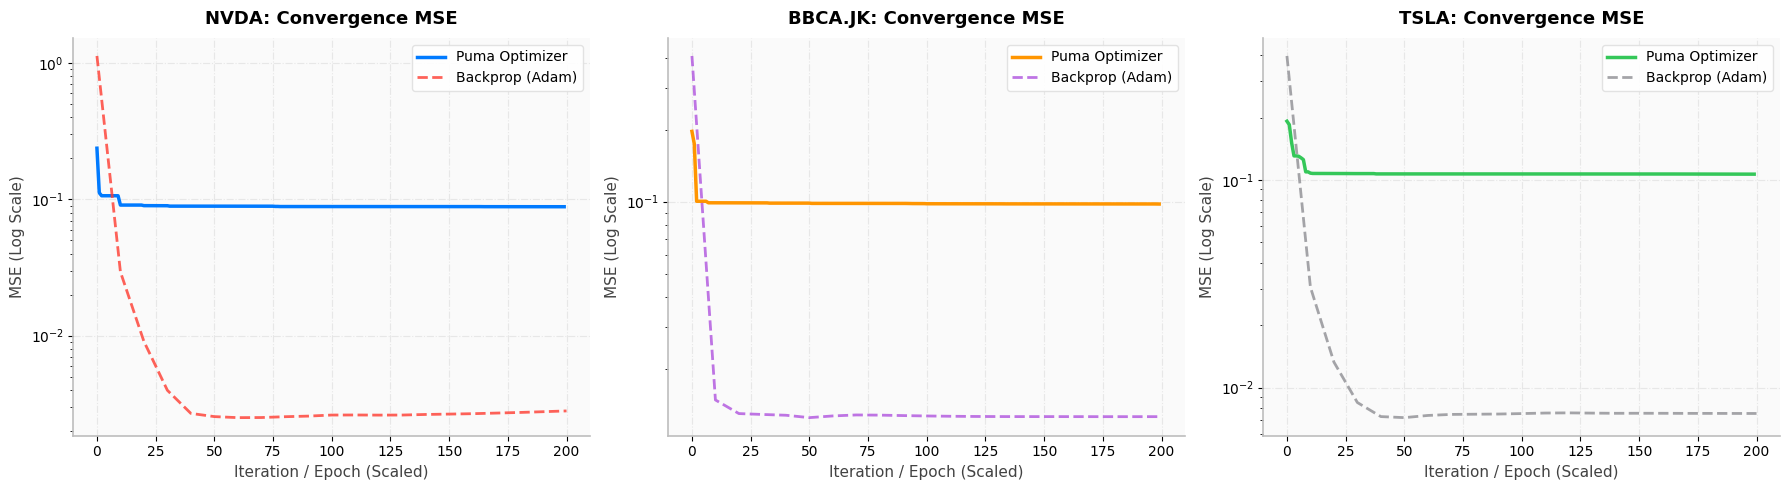

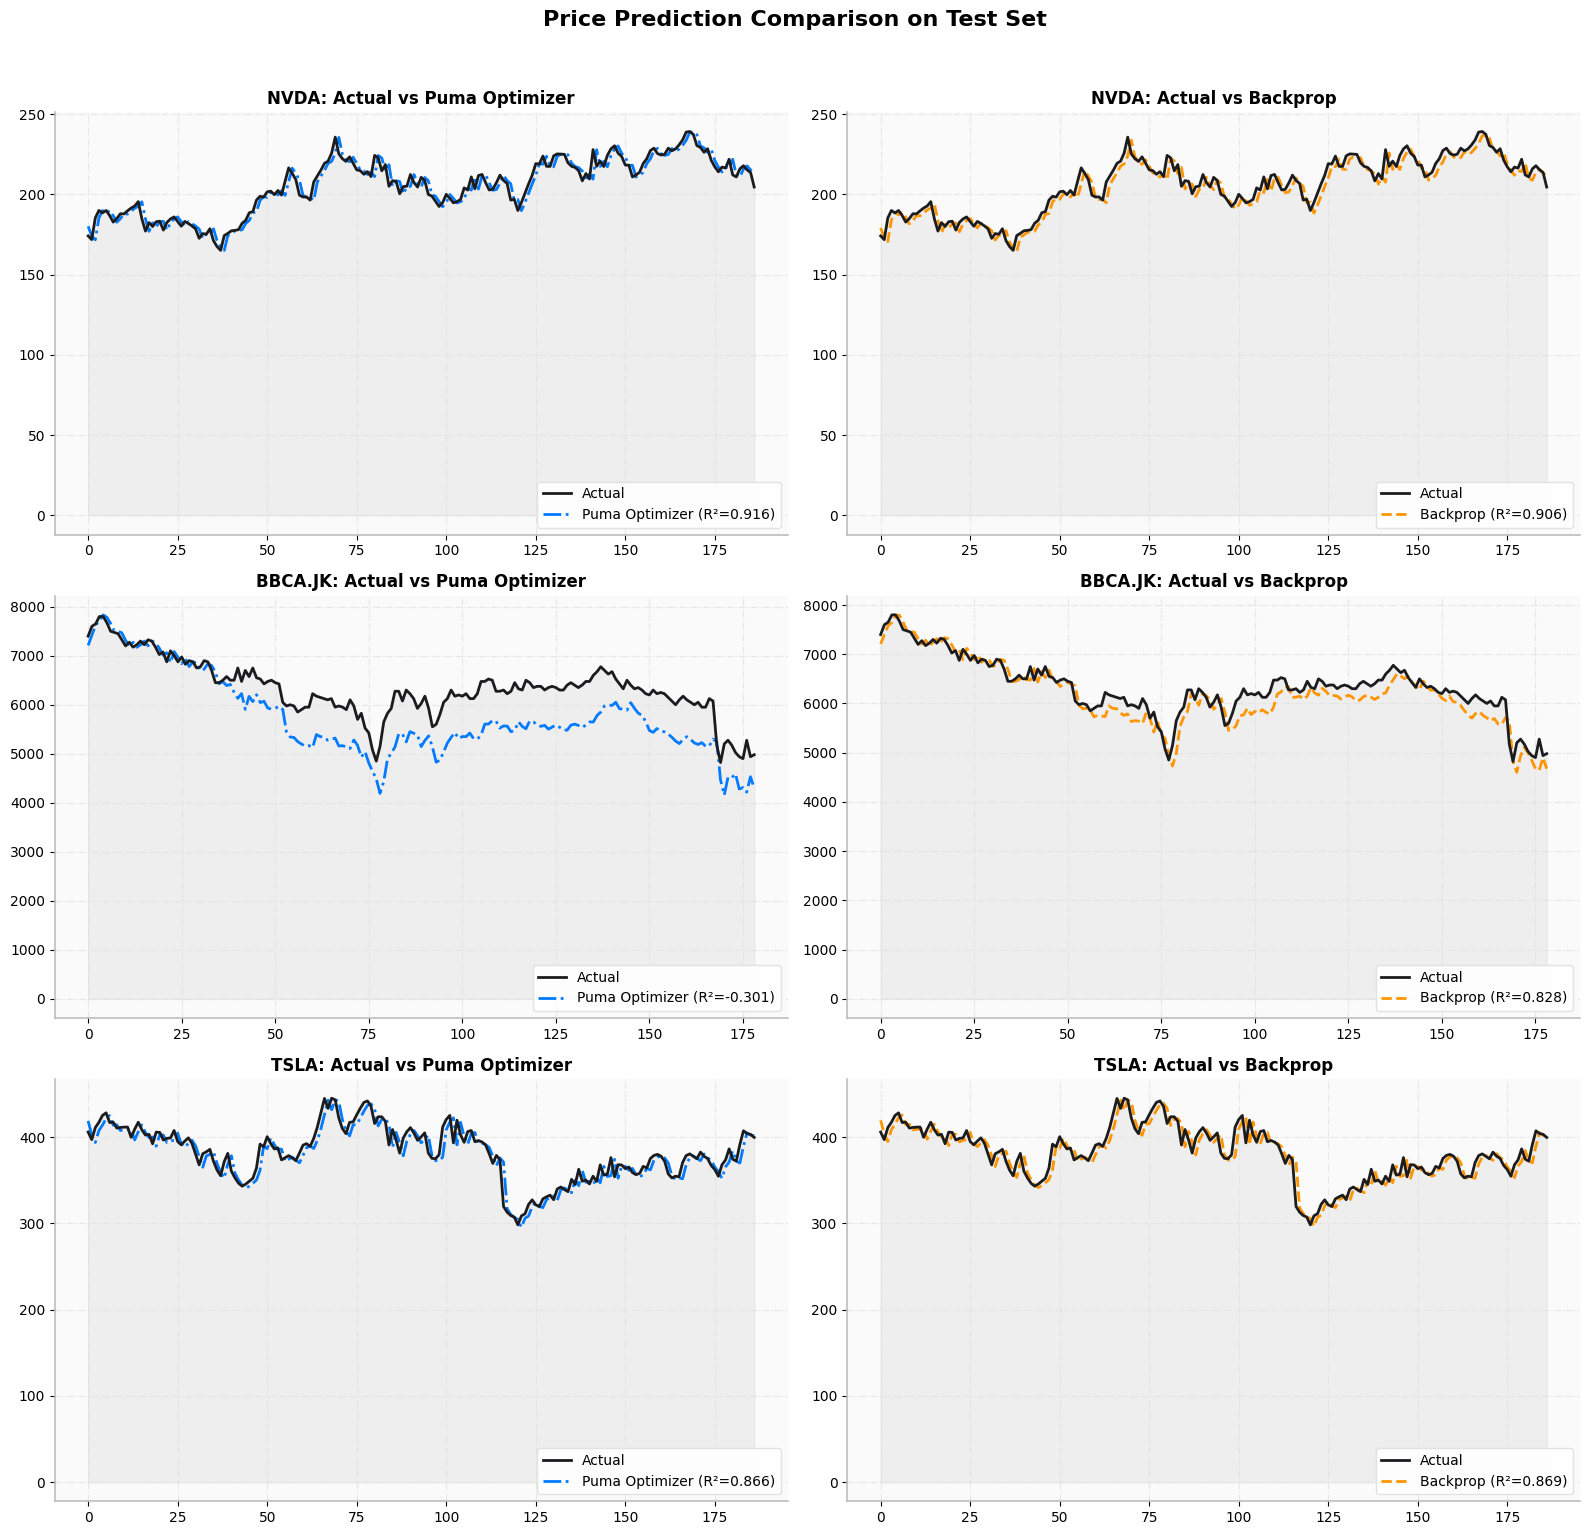


[*] Exporting all evaluation metrics and predictions to CSV...
[+] CSV exports complete.


In [ ]:
if __name__ == "__main__":
    tickers_to_test = ["NVDA", "BBCA.JK", "TSLA"]
    results_compare = {}

    # 1. Run Pipeline
    for ticker in tickers_to_test:
        results_compare[ticker] = run_comparative_pipeline(ticker)

    # 2. Generate and Save Plots
    generate_comparative_plots(results_compare, tickers_to_test)

    # 3. Export Data to CSV
    export_research_data_to_csv(results_compare, tickers_to_test)